# Figure S12B — Residues scored incorrectly per 100, relative to the best CAID3 predictor

For each of the top 40 CAID3 disorder predictors, how many more residues per 100 it labels incorrectly than the best predictor does on CAID3 Disorder-PDB. metapredict V1, V2 and V3 are coloured, and the bracket gives the gap between the best and the tenth-best predictor.

**How it is made.** Same scoring as Figure S12A (each method's own binary calls; metapredict from metapredict 3.1.0 with its default binary calls). The original CAID2 version of this panel bracketed the eleventh-ranked predictor while describing it as the tenth-best; this version uses the tenth-best.

**Output:** `figures/figure_S12B.pdf`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from caid_accuracy import score_caid3_field
from figtools import (FIELD_COLOR, VERSION_COLORS, apply_style, require_metapredict_3_1, save_panel,
                      shared_data_path)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TOP_N = 40

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
scores = score_caid3_field(str(shared_data_path('caid_references', 'caid3_disorder_pdb.fasta')),
                           str(shared_data_path('caid_references', 'caid3_disorder_pdb_results.csv')))
names = list(scores)[:TOP_N]
values = list(scores.values())[:TOP_N]
x = np.arange(1, len(names) + 1)
print(f'{len(scores)} predictors scored; showing the top {TOP_N}')
for name in ['metapredict V1', 'metapredict V2', 'metapredict V3']:
    print(f'{name}: {scores[name]:.2f} correct per 100 (rank {list(scores).index(name) + 1})')


def draw_bars(ax, heights):
    """Black bars for the field with metapredict versions recoloured."""
    ax.bar(x, heights, color=FIELD_COLOR)
    for version, color in VERSION_COLORS.items():
        name = f'metapredict {version}'
        if name in names:
            ax.bar(names.index(name) + 1, heights[names.index(name)], color=color,
                   linewidth=0.5, edgecolor='black')
    ax.set_xticks(x, names, fontsize=7, rotation=45, horizontalalignment='right',
                  rotation_mode='anchor')
    ax.tick_params(axis='y', labelsize=7)
    ax.set_xlim(0.4, len(names) + 0.6)

66 predictors scored; showing the top 40
metapredict V1: 86.83 correct per 100 (rank 23)
metapredict V2: 89.03 correct per 100 (rank 9)
metapredict V3: 89.65 correct per 100 (rank 7)


Wrote figures/figure_S12B.pdf


PosixPath('figures/figure_S12B.pdf')

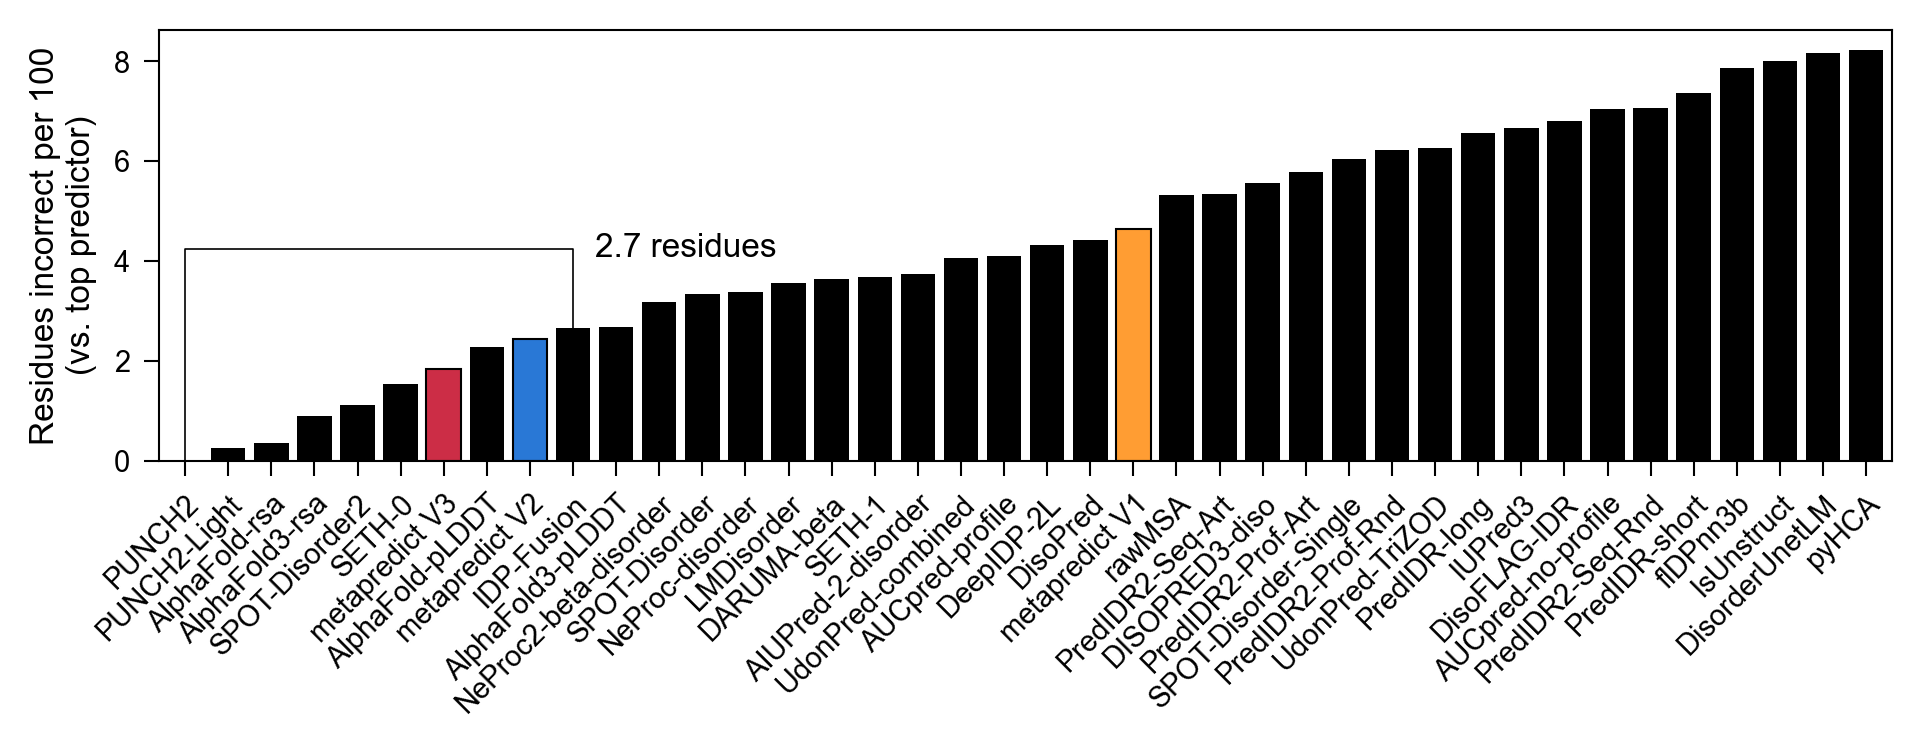

In [3]:
# extra residues incorrect per 100 relative to the best predictor
deficit = [values[0] - v for v in values]
TENTH = 10
BRACKET_Y = 1.6 * deficit[TENTH - 1]

fig, ax = plt.subplots(figsize=(6.5, 2.6), dpi=150)
draw_bars(ax, deficit)
ax.plot([1, 1, TENTH, TENTH], [deficit[0], BRACKET_Y, BRACKET_Y, deficit[TENTH - 1]], '-k', linewidth=0.4)
ax.text(TENTH + 0.5, BRACKET_Y, f'{deficit[TENTH - 1]:.1f} residues', fontsize=8, va='center')
ax.set_ylabel('Residues incorrect per 100\n(vs. top predictor)', fontsize=8)
plt.tight_layout()
save_panel(fig, 'figure_S12B')